# 3. Network pricing: one seat, many journeys

[`02_pricing_engine.ipynb`](02_pricing_engine.ipynb) treats a 3A coach on train 12138 as one product with one fare. That is not how the seats are used. Over one run from Firozpur to Mumbai, the same berth is often sold two or three times: Firozpur → New Delhi overnight, then New Delhi → Bhopal, then Bhusaval → Mumbai. Each origin–destination (O&D) pair is a separate product, and products compete for seats on the legs they share.

Airlines price this way. The standard tool is the **bid price**: every leg of the trip gets a "value of one more seat", and an O&D is sold only at a fare above the sum of the bid prices of the legs it uses (its *displacement cost*). This notebook asks:

> **How much does pricing the coach as a network add over pricing each O&D on its own?**

What comes from data and what is assumed:

| Ingredient | Source |
|---|---|
| Station order and distances | Public timetable, [`data/route_12138.csv`](../data/route_12138.csv) (52 stops, Firozpur Cantt → CSMT, 1,930 km) |
| O&D mix: share of 3A passengers on each origin–destination | Real 3A bookings (`brdpt_code`, `resupto_code`), Aug 2023 – Jul 2024 |
| Booking curve per O&D | Real 3A bookings, journeys from Mar 2025 (60-day booking window) |
| Day-to-day demand and the forecast | Same as [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb): real daily 3A totals, weekday / last-year forecast |
| Fares per O&D | Published 3A Mail/Express fare table, effective 1 Jul 2025, plus reservation fee and superfast charge |
| Price sensitivity, overall demand level | **Assumed**: tested over a range, as in [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb) |

The code is in [`src/network_sim.py`](../src/network_sim.py), and it is tested in [`tests/test_network_sim.py`](../tests/test_network_sim.py).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from data_loader import load_bookings, daily_totals
from pricing_sim import HORIZON, CAPACITY, FARE_LEVELS, BASE_IDX, demand_levels, forecast_levels
from network_sim import (NODES, CLOSED, station_order, map_to_nodes, od_bookings, network_from_bookings,
                         network_lp, leg_bid_prices, segment_quotas, NetworkFixedFare, StaticNetworkFares,
                         SegmentOptimizer, BidPriceLP, BidPriceDecomposition, evaluate_network,
                         summarize_network, simulate_network, random_customers, PlansWith)

pd.set_option("display.precision", 1)
pd.set_option("display.width", 200)
COLUMNS = ["revenue", "passengers", "seat_km_load_%", "revenue_per_pax", "closed_%", "uplift_vs_fixed_%",
           "uplift_ci_%", "passengers_vs_fixed_%", "share_of_lp_bound_%"]

## 1. The route and who travels where

First, the real load profile: how many 3A passengers are on board, on average, between each pair of consecutive stops.

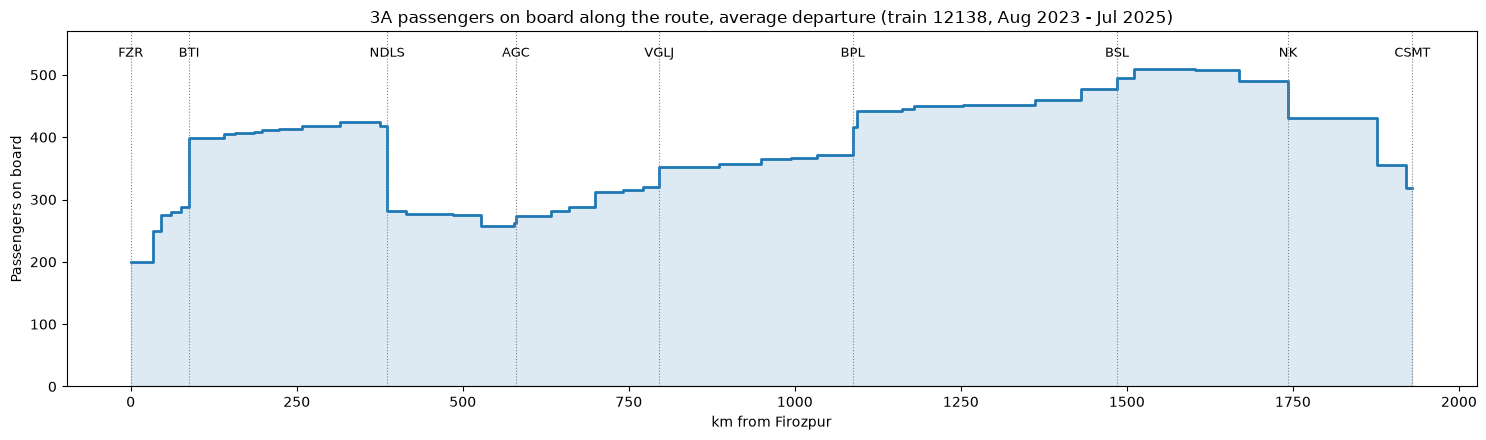

Busiest stretch: 509 on board (near JL); quietest after Delhi: 258 (near Mathura).
226 passengers a day get off at New Delhi, and their berths are sold again southwards.


In [2]:
stations = station_order("../data/route_12138.csv")
bookings = load_bookings(cls="3A")
journey = pd.to_datetime(bookings.journey_date)

pos = {c: i for i, c in enumerate(stations.code)}
o, d = bookings.brdpt_code.map(pos).to_numpy(), bookings.resupto_code.map(pos).to_numpy()
n_days = bookings.journey_date.nunique()
on_board = np.zeros(len(stations) - 1)
for oi, di, p in zip(o, d, bookings.PSGN.to_numpy()):
    on_board[oi:di] += p
on_board /= n_days

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.step(stations.km, np.append(on_board, on_board[-1]), where="post", color="tab:blue", lw=2)
ax.fill_between(stations.km, np.append(on_board, on_board[-1]), step="post", alpha=0.15, color="tab:blue")
for n in NODES:
    km = stations.set_index("code").km[n]
    ax.axvline(km, color="gray", ls=":", lw=0.8)
    ax.text(km, on_board.max() * 1.04, n, ha="center", fontsize=9)
ax.set(title="3A passengers on board along the route, average departure (train 12138, Aug 2023 - Jul 2025)",
       xlabel="km from Firozpur", ylabel="Passengers on board", ylim=(0, on_board.max() * 1.12))
plt.tight_layout()
plt.show()

leaving_ndls = bookings[bookings.resupto_code == "NDLS"].PSGN.sum() / n_days
print(f"Busiest stretch: {on_board.max():.0f} on board (near {stations.code[on_board.argmax()]}); "
      f"quietest after Delhi: {on_board[pos['NDLS']:pos['VGLJ']].min():.0f} (near Mathura).")
print(f"{leaving_ndls:.0f} passengers a day get off at New Delhi, and their berths are sold again southwards.")

The coach is busy in two places: Punjab → Delhi, and Bhopal → Nashik. In between, around Mathura and Agra, it is a third emptier. A seat sold Firozpur → Mumbai uses both busy stretches. Two separate tickets, Firozpur → Delhi and Bhopal → Mumbai, use the same two stretches and earn more. Getting this trade-off right is the job of network pricing.

To keep the model readable, the 52 stops are grouped to the nearest of 9 key stations, which gives **8 legs** and **36 O&D products**. The coach has 90 seats on every leg.

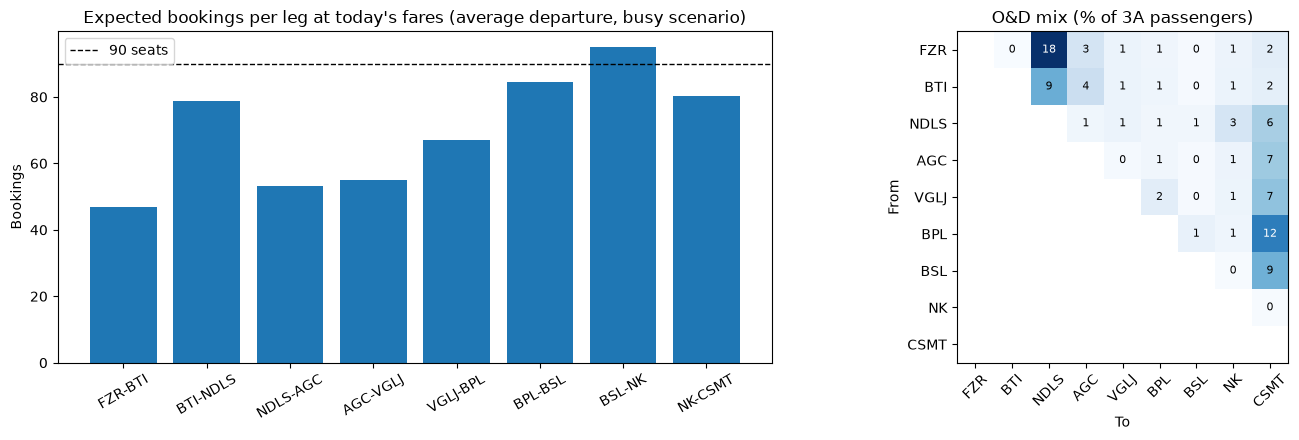

,km,base fare (₹),share of passengers %,book within 7 days %,quota seats
O&D,,,,,
FZR-NDLS,386,673.0,17.8,64.5,36
BPL-CSMT,843,1167.0,12.5,52.2,21
BTI-NDLS,298,531.0,8.9,63.1,18
BSL-CSMT,445,740.0,8.8,51.2,15
VGLJ-CSMT,1134,1394.0,7.3,54.4,12
AGC-CSMT,1350,1543.0,6.7,53.1,11
NDLS-CSMT,1544,1677.0,6.1,54.0,10
BTI-AGC,492,794.0,4.0,51.8,8
FZR-AGC,580,912.0,3.2,56.0,7


Trips that start and end at the same key station after grouping (dropped): 0.7% of passengers.


In [3]:
SHARE_PERIOD = journey < "2024-08-01"            # O&D mix from the training year only
CURVE_PERIOD = journey >= "2025-03-01"           # booking curves from the 60-day-window period, as in PricingAgent
net = network_from_bookings(bookings[CURVE_PERIOD], stations, share_bookings=bookings[SHARE_PERIOD],
                            elasticity=1.2, peak_demand_at_base=95)

legs = [f"{a}-{b}" for a, b in zip(net.nodes[:-1], net.nodes[1:])]
within_week = np.array([c[:8].sum() for c in net.curves])
products = pd.DataFrame({"O&D": net.labels, "km": net.km, "base fare (₹)": net.base_fare,
                         "share of passengers %": 100 * net.share, "book within 7 days %": 100 * within_week,
                         "quota seats": segment_quotas(net)})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(legs, net.leg_load(), color="tab:blue")
axes[0].axhline(CAPACITY, color="black", ls="--", lw=1, label="90 seats")
axes[0].set(title="Expected bookings per leg at today's fares (average departure, busy scenario)",
            ylabel="Bookings")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
mix = np.full((len(NODES), len(NODES)), np.nan)
mix[net.od[:, 0], net.od[:, 1]] = 100 * net.share
im = axes[1].imshow(mix, cmap="Blues")
axes[1].set_xticks(range(len(NODES)), NODES, rotation=45)
axes[1].set_yticks(range(len(NODES)), NODES)
axes[1].set(title="O&D mix (% of 3A passengers)", xlabel="To", ylabel="From")
for (i, j), v in np.ndenumerate(mix):
    if not np.isnan(v):
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 10 else "black")
plt.tight_layout()
plt.show()
display(products.sort_values("share of passengers %", ascending=False).head(12).set_index("O&D"))
dropped = 1 - od_bookings(bookings[SHARE_PERIOD], stations).PSGN.sum() / bookings[SHARE_PERIOD].PSGN.sum()
print(f"Trips that start and end at the same key station after grouping (dropped): {100 * dropped:.1f}% of passengers.")

**The demand scale is an assumption.** The data show how passengers split across O&Ds, but not how many would book one 90-seat coach. As in [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb), we test two levels: an average departure brings **75** or **95** bookings at today's fares on the busiest leg (Bhusaval → Nashik). The other legs follow the real O&D mix, so they are 50–90% as busy.

## 2. The pricing policies

Every O&D can be priced at 0.85×–1.30× its base fare, the same range as [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb). All policies see the same pre-departure forecast.

| Policy | What it does |
|---|---|
| **Fixed fare (today)** | Every O&D at its base fare, first come first served. |
| **Network LP prices, first come first served** | One price per O&D for the whole booking window, chosen by a network LP (below), then no seat control. |
| **Per-segment optimizer, leg-agnostic** | `ForecastOptimizer` from [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb), run on each O&D separately. Each O&D sees the seats left on its own path, but not that 20+ other O&Ds want the same seats. |
| **Per-segment optimizer, fixed seat quotas** | The coach is split up front into a quota per O&D, sized to its demand on its busiest leg, like Indian Railways' station quotas. Then `ForecastOptimizer` prices each O&D within its quota. |
| **Network bid prices (LP, re-solved every 7 days)** | Each week, solve a *deterministic LP*: treat forecast demand as certain, choose how long to sell each O&D at each fare, and keep every leg within the seats it has left. The LP's shadow prices are the **bid prices**, ₹ per seat per leg. Each O&D is then priced to maximize expected bookings × (fare − sum of the bid prices on its legs). If no fare covers that sum, the O&D is closed. |
| **Network bid prices (DP by leg)** | The same pricing rule, but bid prices come from a **dynamic program per leg** (DP decomposition). Each leg's DP values its own seats, and the other legs' seats are valued at the LP bid prices. The bid price moves with every booking and every day, not once a week. |
| *Bid prices, told true demand* | The DP-by-leg policy given each departure's true demand level. It shows how much better forecasts would add. Not deployable. |

We also report each policy's revenue as a share of the **LP upper bound**: the revenue if demand were known and arrived exactly as forecast. No policy can beat it on average.

What do bid prices look like? Below are the bid prices for the busy scenario when booking opens, on a quiet, an average and a busy departure.

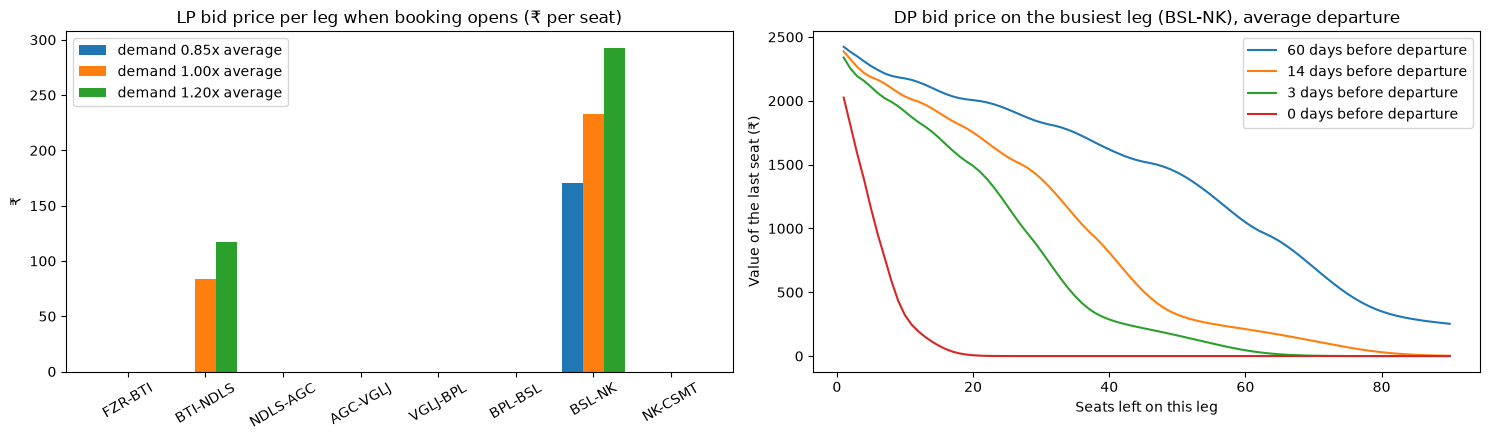

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
width = 0.27
for k, level in enumerate([0.85, 1.0, 1.2]):
    _, lp_bids, _ = network_lp(net, level, np.full(net.n_legs, CAPACITY), HORIZON)
    axes[0].bar(np.arange(net.n_legs) + (k - 1) * width, lp_bids, width, label=f"demand {level:.2f}x average")
axes[0].set_xticks(range(net.n_legs), legs, rotation=30)
axes[0].set(title="LP bid price per leg when booking opens (₹ per seat)", ylabel="₹")
axes[0].legend()

bids = leg_bid_prices(net, 1.0)
busiest = int(np.argmax(net.leg_load()))
for days_out in [60, 14, 3, 0]:
    axes[1].plot(np.arange(1, CAPACITY + 1), bids[days_out, busiest, 1:], label=f"{days_out} days before departure")
axes[1].set(title=f"DP bid price on the busiest leg ({legs[busiest]}), average departure",
            xlabel="Seats left on this leg", ylabel="Value of the last seat (₹)")
axes[1].legend()
plt.tight_layout()
plt.show()

Bid prices are zero on legs with spare seats and positive only where seats are scarce. On the busiest leg, a seat is worth more the fewer seats are left and the more of the booking window remains. A Firozpur → Delhi passenger therefore "pays" only for the Bathinda → Delhi seat. A Firozpur → Mumbai passenger pays for both busy stretches.

## 3. Head-to-head on unseen departures

As in [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb), there are four scenarios: two levels of price sensitivity (elasticity 1.2 and 0.8) × two demand levels (75 and 95 bookings on the busiest leg). Each policy runs on every third departure from Aug 2024 – Jul 2025 (122 unseen departures). Each departure gets 10 booking windows, and every policy faces exactly the same random customers.

In [5]:
daily = daily_totals(bookings)
train = daily[daily.journey_date < "2024-08-01"]
test = daily[daily.journey_date >= "2024-08-01"]
test_levels, test_forecasts = demand_levels(test, train).iloc[::3], forecast_levels(test, train).iloc[::3]

SCENARIOS = {"Price-sensitive, spare seats": (1.2, 75), "Price-sensitive, oversubscribed": (1.2, 95),
             "Less price-sensitive, spare seats": (0.8, 75), "Less price-sensitive, oversubscribed": (0.8, 95)}
SINGLE = ["Per-segment optimizer, leg-agnostic", "Per-segment optimizer, fixed seat quotas"]
NETWORK = "Network bid prices (DP by leg)"
summaries, nets = {}, {}
for label, (elasticity, demand) in SCENARIOS.items():
    n = network_from_bookings(bookings[CURVE_PERIOD], stations, share_bookings=bookings[SHARE_PERIOD],
                              elasticity=elasticity, peak_demand_at_base=demand)
    policies = [NetworkFixedFare(), StaticNetworkFares(), SegmentOptimizer(), SegmentOptimizer(quotas=True),
                BidPriceLP(resolve_every=7), BidPriceDecomposition()]
    results = evaluate_network(policies, n, test_levels, test_forecasts, runs_per_departure=10)
    summaries[label], nets[label] = summarize_network(results), n
    print(f"\n=== {label} (elasticity {elasticity}, {demand} bookings on the busiest leg at today's fares) ===")
    display(summaries[label][COLUMNS])


=== Price-sensitive, spare seats (elasticity 1.2, 75 bookings on the busiest leg at today's fares) ===


,revenue,passengers,seat_km_load_%,revenue_per_pax,closed_%,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%,share_of_lp_bound_%
policy,,,,,,,,,
"Per-segment optimizer, fixed seat quotas",141007.1,139.7,60.7,1009.3,5.1,-4.0,0.2,0.3,92.3
"Per-segment optimizer, leg-agnostic",145995.0,163.7,74.6,891.9,0.0,-0.6,0.3,17.5,95.6
Fixed fare (today),146923.3,139.3,64.0,1054.9,0.0,0.0,0.0,0.0,96.2
"Network LP prices, first come first served",147540.5,162.6,74.8,907.1,0.0,0.4,0.3,16.8,96.6
"Network bid prices (LP, re-solved every 7 days)",149196.2,162.6,75.0,917.3,0.1,1.5,0.2,16.8,97.7
Network bid prices (DP by leg),150595.9,160.8,74.0,936.4,0.0,2.5,0.2,15.5,98.6
"Bid prices, told true demand",150739.0,160.6,73.9,938.4,0.0,2.6,0.2,15.3,98.7



=== Price-sensitive, oversubscribed (elasticity 1.2, 95 bookings on the busiest leg at today's fares) ===


,revenue,passengers,seat_km_load_%,revenue_per_pax,closed_%,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%,share_of_lp_bound_%
policy,,,,,,,,,
"Per-segment optimizer, leg-agnostic",162085.1,183.1,82.0,885.0,0.0,-7.9,0.3,8.9,85.8
"Per-segment optimizer, fixed seat quotas",170321.1,151.5,65.5,1124.4,6.1,-3.2,0.3,-9.9,90.1
Fixed fare (today),175961.3,168.2,76.4,1046.4,0.0,0.0,0.0,0.0,93.1
"Network LP prices, first come first served",178986.7,177.7,81.7,1007.2,0.0,1.7,0.2,5.7,94.7
"Network bid prices (LP, re-solved every 7 days)",182126.4,179.3,82.5,1015.7,0.2,3.5,0.3,6.6,96.4
Network bid prices (DP by leg),184837.5,177.1,80.3,1043.5,0.1,5.0,0.3,5.3,97.8
"Bid prices, told true demand",185151.1,177.2,80.3,1044.7,0.1,5.2,0.3,5.4,98.0



=== Less price-sensitive, spare seats (elasticity 0.8, 75 bookings on the busiest leg at today's fares) ===


,revenue,passengers,seat_km_load_%,revenue_per_pax,closed_%,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%,share_of_lp_bound_%
policy,,,,,,,,,
Fixed fare (today),146923.3,139.3,64.0,1054.9,0.0,0.0,0.0,0.0,93.8
"Per-segment optimizer, fixed seat quotas",149376.3,109.7,49.9,1361.2,5.4,1.7,0.3,-21.2,95.4
"Bid prices, told true demand",155869.9,113.5,52.3,1372.9,0.0,6.1,0.3,-18.5,99.5
Network bid prices (DP by leg),155871.4,113.5,52.3,1372.9,0.0,6.1,0.3,-18.5,99.5
"Network LP prices, first come first served",155874.3,113.5,52.3,1372.8,0.0,6.1,0.3,-18.5,99.5
"Per-segment optimizer, leg-agnostic",155874.3,113.5,52.3,1372.8,0.0,6.1,0.3,-18.5,99.5
"Network bid prices (LP, re-solved every 7 days)",155876.0,113.5,52.3,1372.9,0.0,6.1,0.3,-18.5,99.5



=== Less price-sensitive, oversubscribed (elasticity 0.8, 95 bookings on the busiest leg at today's fares) ===


,revenue,passengers,seat_km_load_%,revenue_per_pax,closed_%,uplift_vs_fixed_%,uplift_ci_%,passengers_vs_fixed_%,share_of_lp_bound_%
policy,,,,,,,,,
Fixed fare (today),175961.3,168.2,76.4,1046.4,0.0,0.0,0.0,0.0,88.9
"Per-segment optimizer, fixed seat quotas",181304.5,134.1,60.3,1351.8,6.5,3.0,0.3,-20.2,91.6
Network bid prices (DP by leg),195591.3,142.5,65.6,1372.7,0.3,11.2,0.4,-15.3,98.8
"Bid prices, told true demand",195615.2,142.4,65.6,1373.5,0.5,11.2,0.4,-15.3,98.8
"Network LP prices, first come first served",195618.1,142.7,65.6,1370.7,0.0,11.2,0.4,-15.1,98.8
"Per-segment optimizer, leg-agnostic",195618.1,142.7,65.6,1370.7,0.0,11.2,0.4,-15.1,98.8
"Network bid prices (LP, re-solved every 7 days)",195694.3,142.5,65.6,1373.2,0.2,11.2,0.4,-15.3,98.9


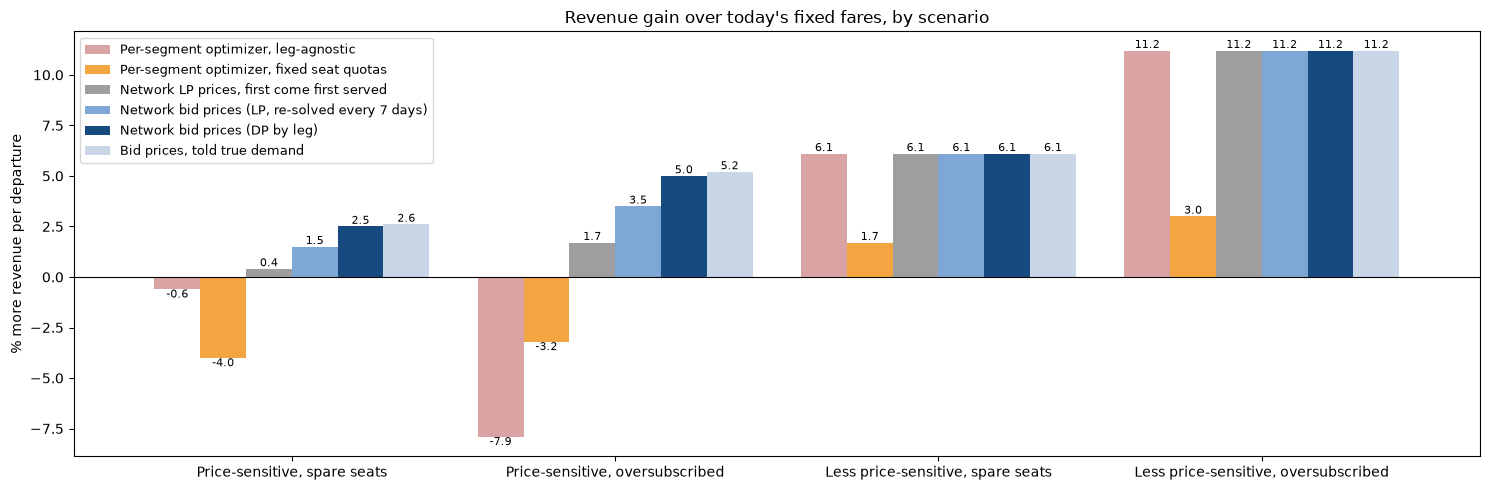

,best single-segment policy,its gain vs fixed %,network bid prices gain vs fixed %,network adds over best single-segment %,"network, share of LP bound %",passengers vs fixed %
"Price-sensitive, spare seats","Per-segment optimizer, leg-agnostic",-0.6,2.5,3.2,98.6,15.5
"Price-sensitive, oversubscribed","Per-segment optimizer, fixed seat quotas",-3.2,5.0,8.5,97.8,5.3
"Less price-sensitive, spare seats","Per-segment optimizer, leg-agnostic",6.1,6.1,-0.0,99.5,-18.5
"Less price-sensitive, oversubscribed","Per-segment optimizer, leg-agnostic",11.2,11.2,-0.0,98.8,-15.3


In [6]:
order = SINGLE + ["Network LP prices, first come first served", "Network bid prices (LP, re-solved every 7 days)",
                  NETWORK, "Bid prices, told true demand"]
uplift = pd.DataFrame({k: s["uplift_vs_fixed_%"] for k, s in summaries.items()}).loc[order]
ax = uplift.T.plot.bar(figsize=(15, 5), width=0.85, rot=0,
                       color=["#d9a3a3", "#f2a541", "#9e9e9e", "#7fa7d6", "#174a7e", "#c9d6e8"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Revenue gain over today's fixed fares, by scenario", ylabel="% more revenue per departure")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

headline = pd.DataFrame({
    "best single-segment policy": {k: s.loc[SINGLE, "uplift_vs_fixed_%"].idxmax() for k, s in summaries.items()},
    "its gain vs fixed %": {k: s.loc[SINGLE, "uplift_vs_fixed_%"].max() for k, s in summaries.items()},
    "network bid prices gain vs fixed %": {k: s.loc[NETWORK, "uplift_vs_fixed_%"] for k, s in summaries.items()},
    "network adds over best single-segment %": {
        k: 100 * (s.loc[NETWORK, "revenue"] / s.loc[SINGLE, "revenue"].max() - 1) for k, s in summaries.items()},
    "network, share of LP bound %": {k: s.loc[NETWORK, "share_of_lp_bound_%"] for k, s in summaries.items()},
    "passengers vs fixed %": {k: s.loc[NETWORK, "passengers_vs_fixed_%"] for k, s in summaries.items()},
})
display(headline.round(1))

## 4. What the network policy does differently

Take the busy, price-sensitive scenario. For each O&D, the chart compares the typical fare offered and the passengers carried under the bid-price policy with the leg-agnostic per-segment optimizer. The "typical fare" is the fare offered on each day, weighted by when that O&D's passengers book.

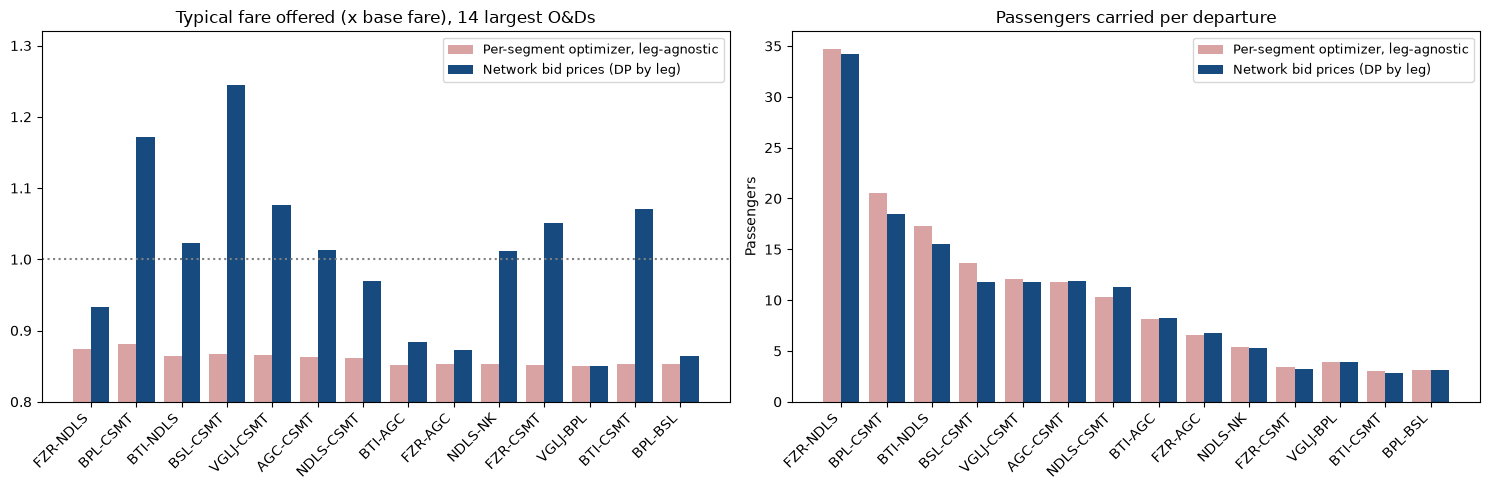

,km,busy legs used,"fare % of base, segment","fare % of base, network","pax, segment","pax, network"
O&D,,,,,,
FZR-NDLS,386,BTI-NDLS,87.5,93.3,34.7,34.2
BPL-CSMT,843,"BPL-BSL, BSL-NK, NK-CSMT",88.0,117.2,20.5,18.5
BTI-NDLS,298,BTI-NDLS,86.4,102.2,17.2,15.5
BSL-CSMT,445,"BSL-NK, NK-CSMT",86.8,124.5,13.6,11.8
VGLJ-CSMT,1134,"BPL-BSL, BSL-NK, NK-CSMT",86.6,107.6,12.0,11.8
AGC-CSMT,1350,"BPL-BSL, BSL-NK, NK-CSMT",86.3,101.4,11.8,11.9
NDLS-CSMT,1544,"BPL-BSL, BSL-NK, NK-CSMT",86.1,97.0,10.3,11.3
BTI-AGC,492,BTI-NDLS,85.2,88.4,8.2,8.2
FZR-AGC,580,BTI-NDLS,85.3,87.3,6.6,6.8


In [7]:
label = "Price-sensitive, oversubscribed"
n = nets[label]
sample_levels, sample_forecasts = test_levels.iloc[::4], test_forecasts.iloc[::4]
typical, carried = {}, {}
for policy in [SegmentOptimizer(), BidPriceDecomposition()]:
    fare_mult, sold_sum = [], []
    for i, (date, level) in enumerate(sample_levels.items()):
        _, sold, fares = simulate_network(policy, n, level, sample_forecasts.iloc[i], customers=random_customers(10, n.n_od, [7, i]))
        weights = n.curves[:, ::-1].T                                                 # (days, J) in simulation order
        mult = np.where(fares == CLOSED, np.nan, FARE_LEVELS[np.maximum(fares, 0)])
        fare_mult.append(np.nansum(mult * weights, axis=1) / np.sum(np.where(np.isnan(mult), 0, weights), axis=1))
        sold_sum.append(sold)
    typical[policy.name] = np.nanmean(np.vstack(fare_mult), axis=0)
    carried[policy.name] = np.vstack(sold_sum).mean(axis=0)

top = np.argsort(-n.demand)[:14]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(top))
for k, (name, color) in enumerate([(SINGLE[0], "#d9a3a3"), (NETWORK, "#174a7e")]):
    axes[0].bar(x + (k - 0.5) * 0.4, typical[name][top], 0.4, color=color, label=name)
    axes[1].bar(x + (k - 0.5) * 0.4, carried[name][top], 0.4, color=color, label=name)
axes[0].axhline(1, color="gray", ls=":")
axes[0].set(title="Typical fare offered (x base fare), 14 largest O&Ds", ylim=(0.8, 1.32))
axes[1].set(title="Passengers carried per departure", ylabel="Passengers")
for ax in axes:
    ax.set_xticks(x, [n.labels[j] for j in top], rotation=45, ha="right")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

table = pd.DataFrame({"O&D": n.labels, "km": n.km,
                      "busy legs used": [", ".join(legs[l] for l in np.flatnonzero(n.incidence[:, j])
                                                   if n.leg_load()[l] > 0.8 * n.leg_load().max()) or "-"
                                         for j in range(n.n_od)],
                      "fare % of base, segment": 100 * typical[SINGLE[0]], "fare % of base, network": 100 * typical[NETWORK],
                      "pax, segment": carried[SINGLE[0]], "pax, network": carried[NETWORK]}).set_index("O&D")
display(table.iloc[top].round(2))

## 5. Where does network pricing pay?

The four scenarios are points on a map. Here we sweep price sensitivity and demand level and measure how much the bid-price policy adds over the *better* of the two single-segment optimizers. This uses every 15th test departure (25 departures) with 5 booking windows each, so each cell is noisier than the tables above.

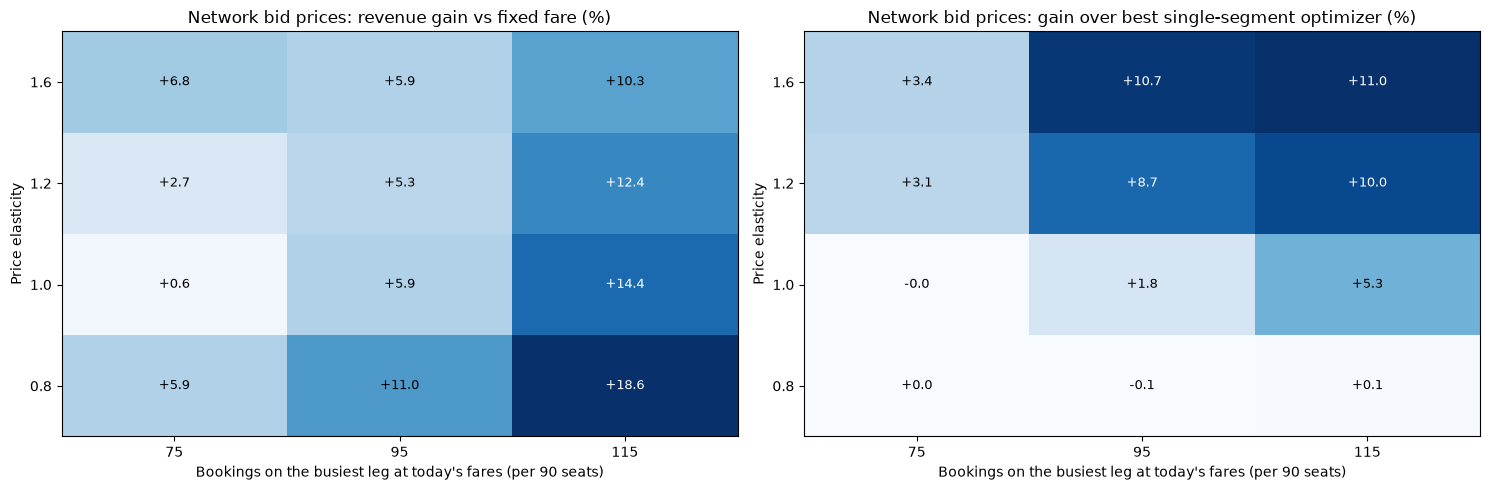

In [8]:
elasticities = [0.8, 1.0, 1.2, 1.6]
demands = [75, 95, 115]
grid_levels, grid_forecasts = test_levels.iloc[::5], test_forecasts.iloc[::5]
grid_net = pd.DataFrame(index=elasticities, columns=demands, dtype=float)
grid_fixed = grid_net.copy()
for e in elasticities:
    for dmd in demands:
        g = network_from_bookings(bookings[CURVE_PERIOD], stations, share_bookings=bookings[SHARE_PERIOD],
                                  elasticity=e, peak_demand_at_base=dmd)
        s = summarize_network(evaluate_network([NetworkFixedFare(), SegmentOptimizer(), SegmentOptimizer(quotas=True),
                                                BidPriceDecomposition()], g, grid_levels, grid_forecasts,
                                               runs_per_departure=5, with_ceiling=False))
        grid_net.loc[e, dmd] = 100 * (s.loc[NETWORK, "revenue"] / s.loc[SINGLE, "revenue"].max() - 1)
        grid_fixed.loc[e, dmd] = s.loc[NETWORK, "uplift_vs_fixed_%"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, grid, title in [(axes[0], grid_fixed, "Network bid prices: revenue gain vs fixed fare (%)"),
                        (axes[1], grid_net, "Network bid prices: gain over best single-segment optimizer (%)")]:
    lim = np.abs(grid.values).max()
    ax.imshow(grid.values.astype(float), cmap="Blues", aspect="auto", origin="lower", vmin=0, vmax=lim)
    ax.set_xticks(range(len(demands)), [f"{d}" for d in demands])
    ax.set_yticks(range(len(elasticities)), [f"{e}" for e in elasticities])
    ax.set(xlabel="Bookings on the busiest leg at today's fares (per 90 seats)", ylabel="Price elasticity", title=title)
    for i in range(len(elasticities)):
        for j in range(len(demands)):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * lim else "black")
plt.tight_layout()
plt.show()

## 6. What if the price sensitivity is wrong?

Everything above assumes the policies know how price-sensitive passengers are. They don't: fares on this train have never changed, so the elasticity is a guess. Here each policy **plans** with one elasticity while customers **behave** with another. Two cases plan with 1.2 while the truth is 0.8 or 1.6, and two plan with 0.8 or 1.6 while the truth is 1.2. All use the oversubscribed scenario (95 bookings on the busiest leg), every 6th test departure (61 departures) and 10 booking windows each.

For reference, the last column is the same bid-price policy planning with the right elasticity.

In [9]:
BUSY = 95
CASES = [(1.2, 0.8), (1.2, 1.6), (0.8, 1.2), (1.6, 1.2)]          # (elasticity planned with, true elasticity)
RIGHT = "Network bid prices, planned with the right elasticity"
robust_levels, robust_forecasts = test_levels.iloc[::2], test_forecasts.iloc[::2]
robust = {}
for plan_e, true_e in CASES:
    make = lambda e: network_from_bookings(bookings[CURVE_PERIOD], stations, share_bookings=bookings[SHARE_PERIOD],
                                           elasticity=e, peak_demand_at_base=BUSY)
    true_net, plan_net = make(true_e), make(plan_e)
    policies = [NetworkFixedFare()] + [PlansWith(p, plan_net) for p in
                                       [SegmentOptimizer(), SegmentOptimizer(quotas=True), BidPriceDecomposition()]]
    policies.append(BidPriceDecomposition(name=RIGHT))
    s = summarize_network(evaluate_network(policies, true_net, robust_levels, robust_forecasts, runs_per_departure=10,
                                           with_ceiling=False))
    robust[f"plans {plan_e}, true {true_e}"] = {
        "best single-segment gain vs fixed %": s.loc[SINGLE, "uplift_vs_fixed_%"].max(),
        "network bid prices gain vs fixed %": s.loc[NETWORK, "uplift_vs_fixed_%"],
        "network adds over best single-segment %": 100 * (s.loc[NETWORK, "revenue"] / s.loc[SINGLE, "revenue"].max() - 1),
        "95% CI, points": s.loc[NETWORK, "uplift_ci_%"],
        "network, right elasticity, gain vs fixed %": s.loc[RIGHT, "uplift_vs_fixed_%"],
    }
robust = pd.DataFrame(robust).T
display(robust.round(1))

,best single-segment gain vs fixed %,network bid prices gain vs fixed %,network adds over best single-segment %,"95% CI, points","network, right elasticity, gain vs fixed %"
"plans 1.2, true 0.8",-0.2,5.4,5.6,0.6,11.2
"plans 1.2, true 1.6",-5.9,5.1,11.7,0.4,5.5
"plans 0.8, true 1.2",1.0,1.0,-0.0,0.6,5.0
"plans 1.6, true 1.2",-4.2,4.6,9.2,0.4,5.0


**Network bid prices still beat the per-segment optimizers in three of the four cases, and never do worse.**

- **Planning with the wrong elasticity, either way round, rarely costs the network its lead.** In three cases, network bid prices earn +4.6% to +5.4% over fixed fares and stay **+5.6% to +11.7% ahead of the best single-segment pricer**. The per-segment optimizers fall to between −5.9% and −0.2%.
- **The costly mistake is assuming passengers are *less* price-sensitive than they are.** Planning with 0.8 when the truth is 1.2 puts every O&D at the +30% cap, as in the 0.8 scenarios above. Then the network policy and the leg-agnostic optimizer price identically. Both earn only +1.0%, against +5.0% for the network policy planned with the right elasticity. The policy still does not fall below today's fares.
- **Assuming passengers are *more* price-sensitive costs less.** Planning with 1.6 when the truth is 1.2 earns +4.6%, against +5.0% when planned right. Planning with 1.2 when the truth is 1.6 earns +5.1% against +5.5%.
- **The one large shortfall is a missed opportunity, not a loss.** Planning with 1.2 when passengers are less sensitive (0.8) earns +5.4%, about half of the +11.2% available, because fares are not raised far enough.

In practice: start from a cautious (higher) elasticity, and use a live fare test to measure the real one.

## Takeaways

- **When passengers are price-sensitive, pricing the coach as a network is worth +3% to +9% over pricing each journey on its own.** In the busy, price-sensitive scenario, network bid prices earn **+5.0%** more than today's fixed fares. The best single-segment approach loses money: **−3.2%** with fixed seat quotas, and −7.9% for the leg-agnostic optimizer. The network approach is therefore **+8.5% ahead of the best single-segment pricer**. With spare seats the figures are +2.5% vs −0.6%, which puts the network +3.2% ahead.
- **Pricing each journey on its own can be worse than not pricing at all.** The `ForecastOptimizer` that works well for a whole coach goes wrong when every O&D runs its own copy. Each copy sees "90 seats left" and discounts to fill them, but 20 other O&Ds are discounting into the same seats. Splitting the coach into fixed quotas avoids that, but then seats sit empty in one quota while another O&D turns passengers away.
- **The network policy raises fares only where seats are scarce.** Seats are tightest between Bhopal and Nashik. Journeys that cross that stretch (Bhopal → Mumbai, Bhusaval → Mumbai, and the long-haul trips from the north) are priced at 100–125% of the base fare, against about 86% under the per-segment optimizer. Journeys on the half-empty Delhi → Jhansi stretch stay discounted. It closes an O&D on fewer than 0.5% of O&D-days, so almost every passenger is still offered a fare.
- **It works with today's forecast.** The DP-by-leg bid prices come within 0.3 points of the same policy told each departure's true demand. They also reach 98–99% of the LP upper bound, which no policy can exceed on average.
- **Most of the gain comes from updating the seat values often.** One set of network-optimal prices, held for the whole window, earns about a third of the gain (+1.7%). Re-solving the LP weekly earns about two-thirds (+3.5%). Updating bid prices with every booking, via the DP by leg, earns all of it (+5.0%).
- **When passengers are not price-sensitive, the network adds nothing, because the +30% fare cap binds.** At elasticity 0.8 every sensible policy puts every O&D at the cap. They all earn the same (+6.1% and +11.2%), and there is nothing left to coordinate. The map in section 5 shows the network gain growing with both price sensitivity and demand, reaching about +10% for busy trains with elastic demand.
- **The network lead survives a wrong guess about price sensitivity.** Planning with elasticity 1.2 when the truth is 0.8 or 1.6, or with 0.8 or 1.6 when the truth is 1.2, network bid prices still beat the best per-segment optimizer by +5.6% to +11.7% in three of the four cases. They tie in the fourth: planning with 0.8 pushes every policy to the fare cap. Overestimating price sensitivity costs about half a point. Underestimating it costs up to 4 to 6 points of gain, but never falls below today's fares.

**What this means for the project:** if Indian Railways adopts dynamic pricing on a multi-stop train, it should be built as O&D network pricing with bid prices, not as one optimizer per ticket type. That is the same lesson airlines learned when they moved from leg-based to O&D revenue management.

### Caveats

- **Price sensitivity is assumed, as in [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb).** The same elasticity is used for every O&D. In reality, short business trips and long family trips probably differ, and the network gain depends on that difference. Section 6 tests what happens when the assumed elasticity is wrong.
- **Demand is "independent".** A passenger turned away from Bhopal → Mumbai does not switch to boarding at Itarsi, or to a cheaper class. Modern airline systems model these choices; this simulator does not.
- **The O&D mix is measured from bookings, which are capped by the seats available.** Waitlisted passengers are missing, so true demand on the busiest legs is understated. That probably makes the network gain conservative.
- **Every O&D shares the same day-to-day demand level.** In reality the Punjab and Mumbai ends of the route have their own festivals and holidays.
- **The quota comparator is rigid.** Indian Railways releases unused quotas closer to departure, and our version does not, so it somewhat understates what a quota system achieves. The leg-agnostic optimizer is the opposite extreme. The truth for a "single-segment" pricer lies between them.
- **The route is simplified to 9 key stations.** Each of the 52 stops is mapped to its nearest key station, so seats on the intermediate legs are approximated. Trips that start and end at the same key station (0.7% of passengers) are dropped.
- **This is one coach on its own.** Fares are the published 3A fares before GST, the coach has 90 seats as in [`02_pricing_engine.ipynb`](02_pricing_engine.ipynb), and other classes and other trains on the route are ignored.